In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import ParameterGrid

from xgboost import XGBClassifier

In [2]:
# Load datasets
weather = pd.read_csv("weatherData.csv")
locations = pd.read_csv("locationData.csv")

print("Weather shape:", weather.shape)
print("Location shape:", locations.shape)

display(weather.head())
display(locations.head())

weather.info()

Weather shape: (142371, 21)
Location shape: (27, 8)


,location_id,date,weather_code (wmo code),temperature_2m_max (°C),temperature_2m_min (°C),temperature_2m_mean (°C),apparent_temperature_max (°C),apparent_temperature_min (°C),apparent_temperature_mean (°C),daylight_duration (s),...,precipitation_sum (mm),rain_sum (mm),precipitation_hours (h),wind_speed_10m_max (km/h),wind_gusts_10m_max (km/h),wind_direction_10m_dominant (°),shortwave_radiation_sum (MJ/m²),et0_fao_evapotranspiration (mm),sunrise,sunset
0,0,1/1/2010,1,30.1,22.6,26.0,34.5,25.0,29.0,42220.20,...,0.0,0.0,0,12.2,27.4,19,20.92,4.61,06:22,18:05
1,0,1/2/2010,51,30.1,23.7,26.3,33.9,26.1,29.7,42225.71,...,0.1,0.1,1,13.0,27.0,24,17.71,3.91,06:22,18:06
2,0,1/3/2010,51,29.6,23.1,26.0,34.5,26.2,29.9,42231.68,...,0.6,0.6,3,12.3,27.4,17,17.76,3.66,06:22,18:06
3,0,1/4/2010,2,28.9,23.1,25.7,31.7,26.1,28.4,42238.11,...,0.0,0.0,0,17.0,34.6,357,16.50,3.75,06:23,18:07
4,0,1/5/2010,1,28.1,21.3,24.6,30.0,22.9,26.2,42244.99,...,0.0,0.0,0,18.7,37.1,353,23.61,5.00,06:23,18:07


,location_id,latitude,longitude,elevation,utc_offset_seconds,timezone,timezone_abbreviation,city_name
0,0,6.924429,79.90725,4,19800,Asia/Colombo,530,Colombo
1,1,7.065026,79.96622,19,19800,Asia/Colombo,530,Gampaha
2,2,6.572935,80.02519,5,19800,Asia/Colombo,530,Kalutara
3,3,7.275923,80.62659,499,19800,Asia/Colombo,530,Kandy
4,4,7.486819,80.52632,362,19800,Asia/Colombo,530,Matale


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 142371 entries, 0 to 142370
Data columns (total 21 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   location_id                      142371 non-null  int64  
 1   date                             142371 non-null  object 
 2   weather_code (wmo code)          142371 non-null  int64  
 3   temperature_2m_max (°C)          142371 non-null  float64
 4   temperature_2m_min (°C)          142371 non-null  float64
 5   temperature_2m_mean (°C)         142371 non-null  float64
 6   apparent_temperature_max (°C)    142371 non-null  float64
 7   apparent_temperature_min (°C)    142371 non-null  float64
 8   apparent_temperature_mean (°C)   142371 non-null  float64
 9   daylight_duration (s)            142371 non-null  float64
 10  sunshine_duration (s)            142371 non-null  float64
 11  precipitation_sum (mm)           142371 non-null  float64
 12  ra

In [3]:
# Convert date and sort records
weather["date"] = pd.to_datetime(weather["date"])

weather = weather.sort_values(
    ["location_id", "date"]
).reset_index(drop=True)

# Merge weather data with location information
df = weather.merge(
    locations[
        [
            "location_id",
            "city_name",
            "latitude",
            "longitude",
            "elevation"
        ]
    ],
    on="location_id",
    how="left"
)

print("Merged dataset shape:", df.shape)
df.head()

Merged dataset shape: (142371, 25)


,location_id,date,weather_code (wmo code),temperature_2m_max (°C),temperature_2m_min (°C),temperature_2m_mean (°C),apparent_temperature_max (°C),apparent_temperature_min (°C),apparent_temperature_mean (°C),daylight_duration (s),...,wind_gusts_10m_max (km/h),wind_direction_10m_dominant (°),shortwave_radiation_sum (MJ/m²),et0_fao_evapotranspiration (mm),sunrise,sunset,city_name,latitude,longitude,elevation
0,0,2010-01-01,1,30.1,22.6,26.0,34.5,25.0,29.0,42220.20,...,27.4,19,20.92,4.61,06:22,18:05,Colombo,6.924429,79.90725,4
1,0,2010-01-02,51,30.1,23.7,26.3,33.9,26.1,29.7,42225.71,...,27.0,24,17.71,3.91,06:22,18:06,Colombo,6.924429,79.90725,4
2,0,2010-01-03,51,29.6,23.1,26.0,34.5,26.2,29.9,42231.68,...,27.4,17,17.76,3.66,06:22,18:06,Colombo,6.924429,79.90725,4
3,0,2010-01-04,2,28.9,23.1,25.7,31.7,26.1,28.4,42238.11,...,34.6,357,16.50,3.75,06:23,18:07,Colombo,6.924429,79.90725,4
4,0,2010-01-05,1,28.1,21.3,24.6,30.0,22.9,26.2,42244.99,...,37.1,353,23.61,5.00,06:23,18:07,Colombo,6.924429,79.90725,4


In [4]:
# Add the rainfall amount of the following day
df["rain_next_day_mm"] = (
    df.groupby("location_id")["rain_sum (mm)"]
    .shift(-1)
)

# Remove rows where next-day rainfall is unavailable
df = df.dropna(
    subset=["rain_next_day_mm"]
).copy()

# Create binary target
# 1 = more than 1 mm rain tomorrow
# 0 = 1 mm or less
df["rain_tomorrow"] = (
    df["rain_next_day_mm"] > 1.0
).astype(int)

print(df["rain_tomorrow"].value_counts())
print(df["rain_tomorrow"].value_counts(normalize=True) * 100)

rain_tomorrow
1    83223
0    59121
Name: count, dtype: int64
rain_tomorrow
1    58.46611
0    41.53389
Name: proportion, dtype: float64


In [5]:
# Create date-based features
df["month"] = df["date"].dt.month
df["day_of_year"] = df["date"].dt.dayofyear

# Select input features
features = [
    "temperature_2m_max (°C)",
    "temperature_2m_min (°C)",
    "temperature_2m_mean (°C)",
    "apparent_temperature_mean (°C)",
    "sunshine_duration (s)",
    "rain_sum (mm)",
    "precipitation_hours (h)",
    "wind_speed_10m_max (km/h)",
    "wind_gusts_10m_max (km/h)",
    "wind_direction_10m_dominant (°)",
    "shortwave_radiation_sum (MJ/m²)",
    "et0_fao_evapotranspiration (mm)",
    "month",
    "day_of_year",
    "latitude",
    "longitude",
    "elevation"
]

print("Missing values:")
print(df[features].isnull().sum().sum())

Missing values:
0


In [6]:
# Chronological train, validation and test split
train_df = df[df["date"] < "2022-01-01"]

validation_df = df[
    (df["date"] >= "2022-01-01") &
    (df["date"] < "2023-01-01")
]

test_df = df[df["date"] >= "2023-01-01"]

X_train = train_df[features]
y_train = train_df["rain_tomorrow"]

X_val = validation_df[features]
y_val = validation_df["rain_tomorrow"]

X_test = test_df[features]
y_test = test_df["rain_tomorrow"]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 118341
Validation samples: 9855
Testing samples: 14148


In [7]:
# Train an initial Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_val_predictions = rf_model.predict(X_val)

print(
    "Random Forest Validation F1:",
    round(f1_score(y_val, rf_val_predictions), 4)
)

Random Forest Validation F1: 0.8036


In [8]:
# Train an initial XGBoost model
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train, y_train)

xgb_val_predictions = xgb_model.predict(X_val)

print(
    "XGBoost Validation F1:",
    round(f1_score(y_val, xgb_val_predictions), 4)
)

XGBoost Validation F1: 0.8021


In [9]:
# Test a small number of Random Forest configurations
rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [8, 12, 16]
}

rf_results = []

for params in ParameterGrid(rf_param_grid):

    model = RandomForestClassifier(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        min_samples_split=5,
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    rf_results.append({
        "n_estimators": params["n_estimators"],
        "max_depth": params["max_depth"],
        "F1 Score": f1_score(y_val, predictions)
    })

rf_tuning_df = pd.DataFrame(rf_results)

rf_tuning_df.sort_values(
    "F1 Score",
    ascending=False
)

,n_estimators,max_depth,F1 Score
2,300,8,0.808579
1,200,8,0.807812
0,100,8,0.806956
5,300,12,0.804104
8,300,16,0.803890
7,200,16,0.803790
4,200,12,0.803584
3,100,12,0.803236
6,100,16,0.801787


In [10]:
# Test a small number of XGBoost configurations
xgb_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.05, 0.1]
}

xgb_results = []

for params in ParameterGrid(xgb_param_grid):

    model = XGBClassifier(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
        learning_rate=params["learning_rate"],
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)

    xgb_results.append({
        "n_estimators": params["n_estimators"],
        "max_depth": params["max_depth"],
        "learning_rate": params["learning_rate"],
        "F1 Score": f1_score(y_val, predictions)
    })

xgb_tuning_df = pd.DataFrame(xgb_results)

xgb_tuning_df.sort_values(
    "F1 Score",
    ascending=False
)

,n_estimators,max_depth,learning_rate,F1 Score
0,100,3,0.05,0.806566
3,100,5,0.05,0.804198
1,200,3,0.05,0.803708
9,100,3,0.10,0.803617
2,300,3,0.05,0.803422
12,100,5,0.10,0.802717
10,200,3,0.10,0.802649
8,300,7,0.05,0.802493
13,200,5,0.10,0.802129
5,300,5,0.05,0.801671


In [11]:
best_rf = rf_tuning_df.sort_values(
    "F1 Score",
    ascending=False
).iloc[0]

best_xgb = xgb_tuning_df.sort_values(
    "F1 Score",
    ascending=False
).iloc[0]

print("Best RF:")
print(best_rf)

print("\nBest XGBoost:")
print(best_xgb)

Best RF:
n_estimators    300.000000
max_depth         8.000000
F1 Score          0.808579
Name: 2, dtype: float64

Best XGBoost:
n_estimators     100.000000
max_depth          3.000000
learning_rate      0.050000
F1 Score           0.806566
Name: 0, dtype: float64


In [12]:
# Combine training and validation data for final training
train_final_df = pd.concat(
    [train_df, validation_df]
)

X_train_final = train_final_df[features]
y_train_final = train_final_df["rain_tomorrow"]

In [13]:
# Train final Random Forest
final_rf = RandomForestClassifier(
    n_estimators=int(best_rf["n_estimators"]),
    max_depth=int(best_rf["max_depth"]),
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

final_rf.fit(
    X_train_final,
    y_train_final
)

rf_test_predictions = final_rf.predict(X_test)

In [14]:
# Train final XGBoost
final_xgb = XGBClassifier(
    n_estimators=int(best_xgb["n_estimators"]),
    max_depth=int(best_xgb["max_depth"]),
    learning_rate=float(best_xgb["learning_rate"]),
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

final_xgb.fit(
    X_train_final,
    y_train_final
)

xgb_test_predictions = final_xgb.predict(X_test)

In [15]:
# Compare final models on the test dataset
comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, rf_test_predictions),
        accuracy_score(y_test, xgb_test_predictions)
    ],
    "Precision": [
        precision_score(y_test, rf_test_predictions),
        precision_score(y_test, xgb_test_predictions)
    ],
    "Recall": [
        recall_score(y_test, rf_test_predictions),
        recall_score(y_test, xgb_test_predictions)
    ],
    "F1 Score": [
        f1_score(y_test, rf_test_predictions),
        f1_score(y_test, xgb_test_predictions)
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.787885,0.826026,0.822842,0.824431
1,XGBoost,0.786330,0.827346,0.817587,0.822438


In [16]:
# Select the best final model
best_row = comparison.sort_values(
    "F1 Score",
    ascending=False
).iloc[0]

if best_row["Model"] == "XGBoost":
    best_model = final_xgb
else:
    best_model = final_rf

print("Best Model:", best_row["Model"])

Best Model: Random Forest


In [17]:
# Show feature importance of the selected model
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": best_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
5,rain_sum (mm),0.337523
6,precipitation_hours (h),0.278643
11,et0_fao_evapotranspiration (mm),0.111672
10,shortwave_radiation_sum (MJ/m²),0.055516
4,sunshine_duration (s),0.041494
13,day_of_year,0.039399
0,temperature_2m_max (°C),0.027358
12,month,0.022964
2,temperature_2m_mean (°C),0.022623
14,latitude,0.017274


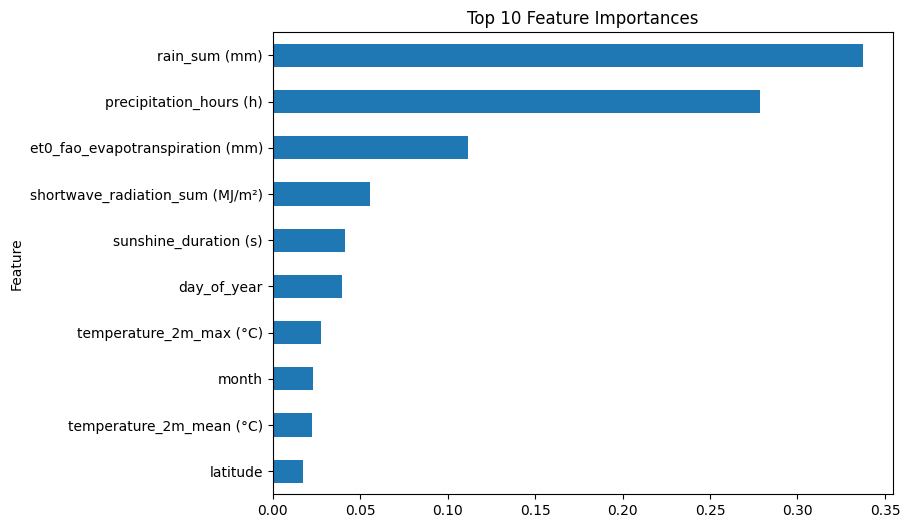

In [18]:
feature_importance.head(10).sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(8, 6)
)

plt.title("Top 10 Feature Importances")
plt.show()

In [19]:
# Save model and dashboard files
joblib.dump(
    best_model,
    "rain_prediction_model.pkl"
)

joblib.dump(
    features,
    "model_features.pkl"
)

comparison.to_csv(
    "model_comparison.csv",
    index=False
)

feature_importance.to_csv(
    "feature_importance.csv",
    index=False
)

locations[
    [
        "location_id",
        "city_name",
        "latitude",
        "longitude",
        "elevation"
    ]
].to_csv(
    "locations_dashboard.csv",
    index=False
)

print("Files saved successfully.")

Files saved successfully.
